# Phase 3: Deep Learning Models (1D CNN and 1D ResNet)

## Step 1: Environment Setup

In [ ]:
# Mounting Drive, making src/ importable, creating output folders, and confirming the GPU is available
from google.colab import drive
drive.mount('/content/drive')

import os, sys
PROJECT = '/content/drive/MyDrive/ecg-project'
OUT = f'{PROJECT}/data_processed'
MODEL_DIR = f'{PROJECT}/models'
PRED_DIR = f'{PROJECT}/results/deep_preds'
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)
sys.path.append(f'{PROJECT}/src')

import tensorflow as tf
import keras
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2: Loading Data for Both Tasks A and B

In [ ]:
# Loading signals once, plus binary (Task A) and multi-label (Task B) targets for every split
import numpy as np, pandas as pd
import data

X, yb, ym = {}, {}, {}
for s in ['train', 'val', 'test']:
    X[s], yb[s] = data.load_split(s, task='binary')
    ym[s] = np.load(f'{OUT}/Ymulti_{s}.npy')
    print(f'{s:5s}: X {X[s].shape} | binary {yb[s].shape} | multi {ym[s].shape}')

train: X (17084, 1000, 12) | binary (17084,) | multi (17084, 5)
val  : X (2146, 1000, 12) | binary (2146,) | multi (2146, 5)
test : X (2158, 1000, 12) | binary (2158,) | multi (2158, 5)


## Step 3: Defining the Models (src/models.py)

In [ ]:
%%writefile /content/drive/MyDrive/ecg-project/src/models.py
# 1D CNN and 1D ResNet architectures for 12-lead ECG classification
import keras
from keras import layers


def conv_bn_relu(x, filters, kernel, stride=1):
    x = layers.Conv1D(filters, kernel, strides=stride, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)


def build_cnn(n_out, input_shape=(1000, 12)):
    """Plain 1D CNN: 5 conv blocks, each halving the time axis, then global pooling."""
    inp = keras.Input(input_shape)
    x = inp
    for filters in [32, 64, 128, 128, 256]:
        x = conv_bn_relu(x, filters, 7)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_out, activation='sigmoid')(x)
    return keras.Model(inp, out, name='cnn1d')


def res_block(x, filters, stride):
    """Two convolutions plus a skip connection (projected when the shape changes)."""
    shortcut = x
    y = conv_bn_relu(x, filters, 7, stride)
    y = layers.Conv1D(filters, 7, padding='same', use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv1D(filters, 1, strides=stride, use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    return layers.ReLU()(layers.Add()([y, shortcut]))


def build_resnet(n_out, input_shape=(1000, 12)):
    """1D ResNet: a wide stem, then 7 residual blocks with growing width and shrinking time axis."""
    inp = keras.Input(input_shape)
    x = conv_bn_relu(inp, 64, 15, stride=2)
    x = layers.MaxPooling1D(3, strides=2, padding='same')(x)
    for filters, stride in [(64, 1), (64, 1), (128, 2), (128, 1), (256, 2), (256, 1), (256, 2)]:
        x = res_block(x, filters, stride)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_out, activation='sigmoid')(x)
    return keras.Model(inp, out, name='resnet1d')


BUILDERS = {'cnn': build_cnn, 'resnet': build_resnet}

Overwriting /content/drive/MyDrive/ecg-project/src/models.py


## Step 4: Inspecting the Architectures

In [ ]:
# Building both models and comparing their size
import importlib, models
importlib.reload(models)

for name, build in models.BUILDERS.items():
    m = build(n_out=5)
    print(f'{name:7s}: {m.count_params():,} parameters | output {m.output_shape}')

cnn    : 422,149 parameters | output (None, 5)
resnet : 3,170,565 parameters | output (None, 5)


## Step 5: Training Function

In [ ]:
# Reusable, resumable training run: seeded, AdamW + cosine LR, early stopping on validation AUROC, saves model and predictions
SEED_BASE = 42

def train_run(model_name, task, seed, epochs=50, batch=64, verbose=2):
    run = f'{model_name}_{task}_s{seed}'
    if os.path.exists(f'{PRED_DIR}/{run}_test.npy'):
        print(f'{run}: already done, skipping')
        return

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED_BASE + seed)
    y = yb if task == 'binary' else ym
    n_out = 1 if task == 'binary' else 5

    model = models.BUILDERS[model_name](n_out)
    steps = int(np.ceil(len(X['train']) / batch)) * epochs
    lr = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=steps)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-2),
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc', multi_label=n_out > 1)])

    train_ds = data.make_dataset(X['train'], y['train'], training=True, batch_size=batch, seed=SEED_BASE + seed)
    val_ds = data.make_dataset(X['val'], y['val'], training=False, batch_size=256)
    stop = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=8, restore_best_weights=True)
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[stop], verbose=verbose)

    model.save(f'{MODEL_DIR}/{run}.keras')
    pd.DataFrame(hist.history).to_csv(f'{PRED_DIR}/{run}_history.csv', index=False)
    for s in ['val', 'test']:                                   # test saved last: it marks the run as complete
        ds = data.make_dataset(X[s], y[s], training=False, batch_size=256)
        np.save(f'{PRED_DIR}/{run}_{s}.npy', model.predict(ds, verbose=0))
    print(f"{run}: best val AUROC {max(hist.history['val_auc']):.3f} after {len(hist.history['loss'])} epochs")

## Step 6: Test Run (CNN, Task A, Seed 0)

In [ ]:
# One full training run to verify the pipeline end to end before launching all the experiments
train_run('cnn', 'binary', seed=0)

from sklearn.metrics import roc_auc_score
p = np.load(f'{PRED_DIR}/cnn_binary_s0_test.npy').ravel()
print(f"Test AUROC: {roc_auc_score(yb['test'], p):.3f}  (XGBoost baseline: 0.917)")

cnn_binary_s0: already done, skipping
Test AUROC: 0.940  (XGBoost baseline: 0.917)


## Step 7: Running All Experiments

In [ ]:
# Running all 20 experiments (2 models × 2 tasks × 5 seeds); completed runs are skipped automatically
for task in ['binary', 'multi']:
    for model_name in ['cnn', 'resnet']:
        for seed in range(5):
            train_run(model_name, task, seed, verbose=0)

cnn_binary_s0: already done, skipping
cnn_binary_s1: already done, skipping
cnn_binary_s2: already done, skipping
cnn_binary_s3: already done, skipping
cnn_binary_s4: already done, skipping
resnet_binary_s0: already done, skipping
resnet_binary_s1: already done, skipping
resnet_binary_s2: already done, skipping
resnet_binary_s3: already done, skipping
resnet_binary_s4: already done, skipping
cnn_multi_s0: already done, skipping
cnn_multi_s1: best val AUROC 0.929 after 15 epochs
cnn_multi_s2: best val AUROC 0.932 after 23 epochs
cnn_multi_s3: best val AUROC 0.929 after 19 epochs
cnn_multi_s4: best val AUROC 0.930 after 23 epochs
resnet_multi_s0: best val AUROC 0.928 after 28 epochs
resnet_multi_s1: best val AUROC 0.928 after 29 epochs
resnet_multi_s2: best val AUROC 0.930 after 23 epochs
resnet_multi_s3: best val AUROC 0.930 after 29 epochs
resnet_multi_s4: best val AUROC 0.930 after 28 epochs


## Step 8: Summarizing Results Across Seeds

In [ ]:
# (8a) Testing AUROC per model and task as mean ± SD over 5 seeds, plus a 5-seed ensemble; save predictions for R
from sklearn.metrics import roc_auc_score

CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
RESULTS = f'{PROJECT}/results'
meta = pd.read_csv(f'{OUT}/metadata.csv', index_col='ecg_id')
test_ids = meta[meta['split'] == 'test'].index

def score(task, y, p):
    return roc_auc_score(y, p.ravel()) if task == 'binary' else roc_auc_score(y, p, average='macro')

rows, per_class = [], {}
out_bin = pd.DataFrame({'y_true': yb['test']}, index=test_ids)
out_multi = pd.DataFrame({f'y_{c}': ym['test'][:, k] for k, c in enumerate(CLASSES)}, index=test_ids)

for task in ['binary', 'multi']:
    y = yb['test'] if task == 'binary' else ym['test']
    for model_name in ['cnn', 'resnet']:
        P = [np.load(f'{PRED_DIR}/{model_name}_{task}_s{s}_test.npy') for s in range(5)]
        aucs = [score(task, y, p) for p in P]
        ens = np.mean(P, axis=0)
        rows.append({'Task': task, 'Model': model_name, 'Mean AUROC': np.mean(aucs),
                     'SD': np.std(aucs, ddof=1), 'Ensemble AUROC': score(task, y, ens)})
        if task == 'binary':
            out_bin[f'p_{model_name}'] = ens.ravel()
        else:
            per_class[model_name] = [np.mean([roc_auc_score(y[:, k], p[:, k]) for p in P]) for k in range(5)]
            for k, c in enumerate(CLASSES):
                out_multi[f'p_{model_name}_{c}'] = ens[:, k]

summary = pd.DataFrame(rows).round(3)
summary.loc[len(summary)] = ['binary', 'xgboost (baseline)', 0.917, np.nan, np.nan]
summary.loc[len(summary)] = ['multi', 'xgboost (baseline)', 0.907, np.nan, np.nan]
summary.to_csv(f'{RESULTS}/deep_summary.csv', index=False)
out_bin.to_csv(f'{RESULTS}/preds_test_deep_binary.csv')
out_multi.to_csv(f'{RESULTS}/preds_test_deep_multilabel.csv')

print(summary.to_string(index=False))
print('\nTask B per-class AUROC (mean over seeds):')
print(pd.DataFrame(per_class, index=CLASSES).assign(xgboost=[0.932, 0.906, 0.927, 0.869, 0.903]).round(3))

  Task              Model  Mean AUROC    SD  Ensemble AUROC
binary                cnn       0.939 0.001           0.943
binary             resnet       0.937 0.001           0.941
 multi                cnn       0.927 0.003           0.933
 multi             resnet       0.927 0.001           0.933
binary xgboost (baseline)       0.917   NaN             NaN
 multi xgboost (baseline)       0.907   NaN             NaN

Task B per-class AUROC (mean over seeds):
        cnn  resnet  xgboost
NORM  0.947   0.945    0.932
MI    0.924   0.924    0.906
STTC  0.937   0.936    0.927
CD    0.923   0.925    0.869
HYP   0.902   0.903    0.903


In [ ]:
# (8b) Choose each deep model's decision threshold on validation (Youden's J on the 5-seed ensemble) and save it for R
from sklearn.metrics import roc_curve

thr_deep = {}
for m in ['cnn', 'resnet']:
    pv = np.mean([np.load(f'{PRED_DIR}/{m}_binary_s{s}_val.npy') for s in range(5)], axis=0).ravel()
    fpr, tpr, t = roc_curve(yb['val'], pv)
    thr_deep[m] = t[np.argmax(tpr - fpr)]

pd.Series(thr_deep, name='Threshold').to_csv(f'{RESULTS}/deep_thresholds.csv')
print(thr_deep)

{'cnn': np.float32(0.4619638), 'resnet': np.float32(0.41974244)}


## Step 9: Learning Curves

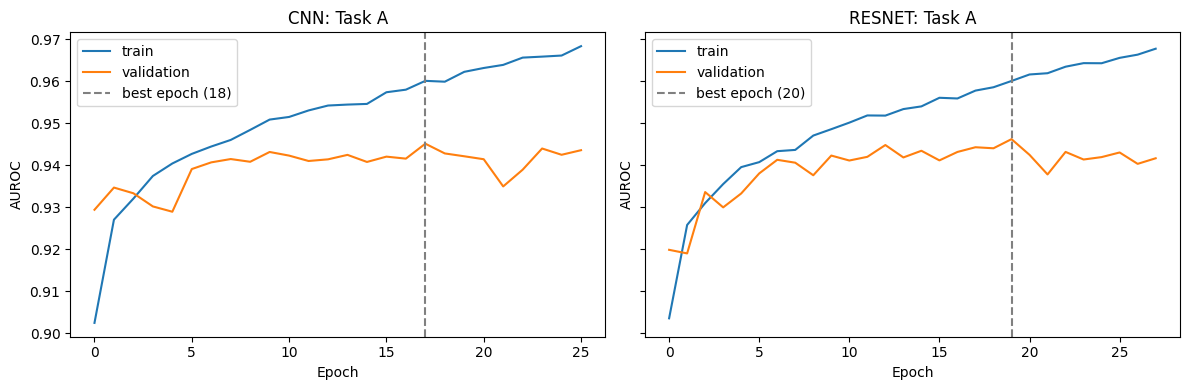

In [ ]:
# Plotting training vs validation AUROC per epoch for seed 0 of each model (Task A)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, model_name in zip(axes, ['cnn', 'resnet']):
    h = pd.read_csv(f'{PRED_DIR}/{model_name}_binary_s0_history.csv')
    ax.plot(h['auc'], label='train')
    ax.plot(h['val_auc'], label='validation')
    best = h['val_auc'].idxmax()
    ax.axvline(best, ls='--', c='gray', label=f'best epoch ({best + 1})')
    ax.set(title=f'{model_name.upper()}: Task A', xlabel='Epoch', ylabel='AUROC')
    ax.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS}/figures/learning_curves_binary.png', dpi=150)
plt.show()

Steo 10: Recaliberation

In [ ]:
# Recalibrating deep-model probabilities with Platt scaling fitted on validation, and save calibrated test predictions
from sklearn.linear_model import LogisticRegression
from scipy.special import logit

def ensemble(m, split):
    return np.mean([np.load(f'{PRED_DIR}/{m}_binary_s{k}_{split}.npy') for k in range(5)], axis=0).ravel()

out = pd.read_csv(f'{RESULTS}/preds_test_deep_binary.csv', index_col='ecg_id')
for m in ['cnn', 'resnet']:
    pv, pt = [np.clip(ensemble(m, s), 1e-6, 1 - 1e-6) for s in ['val', 'test']]
    platt = LogisticRegression(C=1e6).fit(logit(pv).reshape(-1, 1), yb['val'])
    out[f'p_{m}_cal'] = platt.predict_proba(logit(pt).reshape(-1, 1))[:, 1]
out.to_csv(f'{RESULTS}/preds_test_deep_binary.csv')
print(out.filter(like='p_').describe().round(3))

          p_cnn  p_resnet  p_cnn_cal  p_resnet_cal
count  2158.000  2158.000   2158.000      2158.000
mean      0.516     0.527      0.568         0.565
std       0.411     0.405      0.391         0.390
min       0.002     0.002      0.006         0.005
25%       0.078     0.093      0.150         0.145
50%       0.490     0.501      0.625         0.601
75%       0.988     0.990      0.990         0.991
max       1.000     1.000      1.000         1.000
